# LSCNS — Full-vector Fiber Mode Lab v0.1

**2D coupled transverse magnetic field (Hx, Hy) full-vector FDFD eigenmode solver** for straight, isotropic silica fiber cross-sections. It computes complex Ex/Ey/Ez and Hx/Hy/Hz, estimates `n_eff`, then integrates **electric-field intensity** to evaluate MFD and Aeff. This is a **real vector eigenproblem**, not a screenshot or scalar LP01 result; it uses **finite differences (FDFD), not FEM**. No PML / loss extraction.

**Research limitation:** Step-index, graded, concentric multilayer, and trench models use pure-silica Sellmeier + a wavelength-independent Δn approximation. This is neither a manufacturer RI profile nor a calibrated fiber certification. Core-wall HCF/NANF leakage and confinement loss are not supported; a PML/vector FEM research solver is needed separately.

[GitHub source](https://github.com/kimheeseo/LSCNS/tree/main/COMSOL/universal_silica_v01/full_vector) · [Current web tool](https://kimheeseo.github.io/LSCNS/COMSOL/universal_silica_v01/web/)

### Physical definitions

- `n_eff = β/k0` from the **2-component coupled vector H** eigenproblem (Ez and all other fields reconstructed from Maxwell), not scalar LP01.
- Electric intensity **I = |Ex|²+|Ey|²+|Ez|²**.
- `Aeff = [∫I dxdy]² / ∫I² dxdy`.
- **Second-moment MFD** `= 2 sqrt(2 ∫[(x-xc)²+(y-yc)²] I dxdy / ∫I dxdy)`.
- **2D near-field Petermann-II-like MFD** `= 2 sqrt(2 ∫|E|² dxdy / ∫|∇|E||² dxdy)`. This is an estimation convention for general 2D fields. It is not automatically identical to each IEC measurement method. <https://webstore.iec.ch/en/publication/3457>.

This release computes **guided, lossless solid-core modes**. It does not compute HCF confinement loss or a reliable imaginary effective index; any tiny imaginary values are numerical artifacts.

## 1. Dependencies and solver (self-contained offline copy)
Run all cells. You can edit the design parameters in section 2.

In [1]:
%matplotlib inline
import sys, json, math, time
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
# The exact source used for this notebook is embedded to avoid network-dependent installation.
Path('vector_modes.py').write_text('"""Research-grade prototype 2-D full-vector finite-difference eigenmode solver.\nIsotropic nonmagnetic z-invariant dielectrics, lossless; no PML.\nThe Ht=(Hx,Hy) vectorial operator is derived from curl epsilon^-1 curl H=k0² H\nand div(H)=0; Ez is reconstructed from Maxwell curl H.\nAll lengths in um, eps_r is relative dielectric function.\n"""\nfrom dataclasses import dataclass,asdict\nfrom pathlib import Path\nimport json\nimport numpy as np\nfrom scipy.sparse import diags,eye,kron,bmat\nfrom scipy.sparse.linalg import eigs\nfrom scipy.special import jv,kv,jvp,kvp\nfrom scipy.optimize import brentq\n\nB=(0.6961663,0.4079426,0.8974794)\nC=(0.0684043**2,0.1162414**2,9.896161**2)\nC_LIGHT=299792458.0\n\ndef silica_index(w_um):\n    if not .21<w_um<3.7: raise ValueError(\'wavelength outside silica Sellmeier domain\')\n    return float(np.sqrt(1+sum(b*w_um*w_um/(w_um*w_um-c) for b,c in zip(B,C))))\n\n@dataclass(frozen=True)\nclass Configuration:\n    wavelength_nm:float=1550.\n    profile:str=\'step\'\n    core_radius_um:float=5.5\n    delta_n:float=.0034785793846155\n    window_halfwidth_um:float=22.\n    grid_n:int=77\n    graded_alpha:float=2.\n    trench_start_um:float=7.\n    trench_end_um:float=10.\n    trench_delta_n:float=-.001\n    shells:tuple=((5.,.004),(7.,0.),(9.,-.0007))\n    def validate(self):\n        if self.profile not in (\'step\',\'graded\',\'trench\',\'multilayer\'):raise ValueError(\'unsupported profile\')\n        for n in (\'wavelength_nm\',\'core_radius_um\',\'window_halfwidth_um\'):\n            if not np.isfinite(getattr(self,n)) or getattr(self,n)<=0:raise ValueError(n)\n        if not(250<self.wavelength_nm<3600):raise ValueError(\'wavelength\')\n        if not (self.window_halfwidth_um>2.1*self.core_radius_um):raise ValueError(\'domain too small\')\n        if not isinstance(self.grid_n,int) or self.grid_n<29 or self.grid_n>181 or self.grid_n%2==0:raise ValueError(\'grid_n odd [29,181]\')\n        if not np.isfinite(self.delta_n) or self.delta_n<=0 or self.delta_n>.1:raise ValueError(\'delta_n\')\n        if self.profile==\'trench\' and not self.core_radius_um<self.trench_start_um<self.trench_end_um<self.window_halfwidth_um:raise ValueError(\'trench\')\n        if self.profile==\'multilayer\':\n            if not self.shells or self.shells[0][0]<=0 or self.shells[-1][0]>=self.window_halfwidth_um:raise ValueError(\'shells\')\n            if not all(self.shells[i][0]<self.shells[i+1][0] for i in range(len(self.shells)-1)):raise ValueError(\'shell boundaries\')\n        return self\n\ndef make_index(c:Configuration):\n    c.validate()\n    n=c.grid_n;L=c.window_halfwidth_um\n    xy=np.linspace(-L,L,n);dx=xy[1]-xy[0]\n    xx,yy=np.meshgrid(xy,xy,indexing=\'xy\');r=np.hypot(xx,yy)\n    nc=silica_index(c.wavelength_nm/1000)\n    if c.profile==\'step\':offset=np.where(r<c.core_radius_um,c.delta_n,0.)\n    elif c.profile==\'graded\':offset=np.where(r<c.core_radius_um,c.delta_n*np.maximum(1-(r/c.core_radius_um)**c.graded_alpha,0.),0.)\n    elif c.profile==\'trench\':offset=np.where(r<c.core_radius_um,c.delta_n,np.where((r>=c.trench_start_um)&(r<c.trench_end_um),c.trench_delta_n,0.))\n    else:\n        offset=np.zeros_like(r);prev=0.\n        for end,delta in c.shells:\n            offset=np.where((r>=prev)&(r<end),delta,offset);prev=end\n    return xy,nc+offset\n\ndef operators(n:int,d:float):\n    k=n-2\n    D2=diags([np.ones(k-1),-2*np.ones(k),np.ones(k-1)],[-1,0,1],shape=(k,k),format=\'csr\')/d**2\n    D1=diags([-np.ones(k-1),np.ones(k-1)],[-1,1],shape=(k,k),format=\'csr\')/(2*d)\n    eye1=eye(k,format=\'csr\')\n    Dx=kron(eye1,D1,format=\'csr\');Dy=kron(D1,eye1,format=\'csr\')\n    Lap=kron(eye1,D2,format=\'csr\')+kron(D2,eye1,format=\'csr\')\n    return Dx,Dy,Lap\n\ndef integrate_intensity(I,xy):\n    """Full transverse-field intensity integrals over dxdy (finite-difference quadrature).\n\n    I = |Ex|^2 + |Ey|^2 + |Ez|^2, so Aeff = (integral I)^2/(integral I^2).\n    The moment MFD is 2 sqrt(2 <r^2>) centered on the intensity centroid.\n    A separate Petermann-II-like near-field estimate uses f = sqrt(I).\n    """\n    I=np.asarray(I,dtype=float);xy=np.asarray(xy,dtype=float)\n    if I.shape!=(len(xy),len(xy)) or np.any(I<0) or not np.isfinite(I).all():raise ValueError(\'intensity grid\')\n    d=xy[1]-xy[0];A=d*d;power=float(np.sum(I)*A)\n    if power<=0:raise ValueError(\'zero intensity\')\n    xx,yy=np.meshgrid(xy,xy)\n    cx=float(np.sum(I*xx)*A/power);cy=float(np.sum(I*yy)*A/power)\n    moment=float(np.sum(((xx-cx)**2+(yy-cy)**2)*I)*A/power)\n    aeff=power**2/(float(np.sum(I*I))*A)\n    f=np.sqrt(I);fy,fx=np.gradient(f,d,d,edge_order=2)\n    gradient=float(np.sum(fx*fx+fy*fy)*A)\n    return dict(Aeff_um2=aeff,MFD_2nd_um=2*np.sqrt(2*moment),\n                MFD_PII_um=2*np.sqrt(2*power/gradient) if gradient>0 else float(\'nan\'),\n                centroid_x_um=cx,centroid_y_um=cy,power_integral=power)\n\n\ndef solve(c:Configuration,modes=3):\n    xy,ni=make_index(c);n=c.grid_n;d=xy[1]-xy[0];k0=2*np.pi/(c.wavelength_nm/1000)\n    eps=ni**2;gy,gx=np.gradient(np.log(eps),d,d,edge_order=2)\n    select=np.s_[1:-1,1:-1];e=eps[select].ravel();p=ni[select].ravel()\n    gx=diags(gx[select].ravel(),format=\'csr\');gy=diags(gy[select].ravel(),format=\'csr\')\n    Dx,Dy,Lap=operators(n,d)\n    base=Lap+diags(k0*k0*e,format=\'csr\')\n    # H field PDE from Maxwell\'s curl-eps-curl eigenmode and div H=0:\n    # beta² Hx = (lap + k0² eps) Hx - (d_y ln eps) (d_y Hx - d_x Hy)\n    # beta² Hy = (lap + k0² eps) Hy + (d_x ln eps) (d_y Hx - d_x Hy)\n    M=bmat([[base-gy@Dy,gy@Dx],[gx@Dy,base-gx@Dx]],format=\'csc\')\n    v=np.zeros(2*len(e));v[len(e)//2]=1;v[len(e)+len(e)//2]=.7\n    number=min(modes,6)\n    vals,vecs=eigs(M,k=number,sigma=(k0*max(e)**.5)**2+.005,which=\'LM\',v0=v,tol=2e-9,maxiter=3000)\n    modes_out=[]\n    for j in np.argsort(vals.real)[::-1]:\n        eig=vals[j];beta=np.sqrt(eig);neff=beta/k0\n        if abs(neff.imag)>2e-4:continue\n        if not (ni[0,0]+1e-6 < neff.real < ni.max()+2e-3):continue\n        Hx=np.zeros((n,n),complex);Hy=np.zeros((n,n),complex)\n        Hx[select]=vecs[:len(e),j].reshape(n-2,n-2);Hy[select]=vecs[len(e):,j].reshape(n-2,n-2)\n        divH=np.gradient(Hx,d,axis=1)+np.gradient(Hy,d,axis=0)\n        Hz=1j*divH/beta\n        curlx=np.gradient(Hz,d,axis=0)-1j*beta*Hy\n        curly=1j*beta*Hx-np.gradient(Hz,d,axis=1)\n        curlz=np.gradient(Hy,d,axis=1)-np.gradient(Hx,d,axis=0)\n        Ex=1j*curlx/(k0*eps);Ey=1j*curly/(k0*eps);Ez=1j*curlz/(k0*eps)\n        I=np.abs(Ex)**2+np.abs(Ey)**2+np.abs(Ez)**2\n        metrics=integrate_intensity(I,xy)\n        xx,yy=np.meshgrid(xy,xy)\n        hres=np.linalg.norm(M@vecs[:,j]-eig*vecs[:,j])/np.linalg.norm(eig*vecs[:,j])\n        px=float(np.sum(np.abs(Ex)**2)/np.sum(I));py=float(np.sum(np.abs(Ey)**2)/np.sum(I));pz=float(np.sum(np.abs(Ez)**2)/np.sum(I))\n        corepower=I[np.hypot(xx,yy)<=c.core_radius_um].sum()/I.sum()\n        edgepower=(I[:3,:].sum()+I[-3:,:].sum()+I[:,:3].sum()+I[:,-3:].sum())/I.sum()\n        modes_out.append(dict(neff=float(neff.real),neff_imag_numerical=float(neff.imag),Aeff_um2=float(metrics["Aeff_um2"]),MFD_2nd_um=float(metrics["MFD_2nd_um"]),MFD_PII_um=float(metrics["MFD_PII_um"]),\n            residual=float(hres),Ex_intensity_fraction=px,Ey_intensity_fraction=py,Ez_intensity_fraction=pz,core_power_fraction=float(corepower),edge_power_fraction=float(edgepower),field_intensity=I/I.max(),\n            Ex=Ex,Ey=Ey,Ez=Ez,Hx=Hx,Hy=Hy,Hz=Hz))\n    if not modes_out:raise RuntimeError(\'no guided vector mode found; adjust grid/domain\')\n    # sort by field symmetry / highest neff pair; both polarization partners may differ due to mesh\n    return dict(config=c,xy_um=xy,index_map=ni,modes=modes_out,method=\'2D transverse Hx Hy full-vector finite difference; Ez reconstructed from Maxwell\')\n\n\ndef he11_exact_step(c:Configuration):\n    """Independent exact full-vector HE11 characteristic equation, circular step-index only."""\n    if c.profile!=\'step\':raise ValueError(\'HE11 oracle step only\')\n    lam=c.wavelength_nm/1000;k0=2*np.pi/lam;nc=silica_index(lam);nco=nc+c.delta_n;a=c.core_radius_um\n    v=k0*a*np.sqrt(nco*nco-nc*nc)\n    if not 0<v<2.4048255:raise ValueError(\'comparison restricted to V<2.405\')\n    def f(u):\n        w=np.sqrt(v*v-u*u)\n        A=jvp(1,u)/(u*jv(1,u));B=kvp(1,w)/(w*kv(1,w))\n        ne2=nco*nco-u*u/(k0*a)**2\n        return (A+B)*(nco*nco*A+nc*nc*B)-ne2*(1/u/u+1/w/w)**2\n    us=np.linspace(.001,v-.001,300);zs=[f(u) for u in us]\n    roots=[brentq(f,a,b) for a,b,fa,fb in zip(us[:-1],us[1:],zs[:-1],zs[1:]) if np.isfinite(fa) and np.isfinite(fb) and fa*fb<0]\n    if not roots:raise RuntimeError(\'could not bracket exact HE11 root\')\n    return float(np.sqrt(nco*nco-(min(roots)/(k0*a))**2))\n\n\ndef export_result(sol,path,field_stride=2):\n    """Portable JSON for browser import. Full complex fields remain available in .npz."""\n    c=sol[\'config\']; xy=sol[\'xy_um\']; stride=int(field_stride)\n    if stride<1:raise ValueError(\'field_stride >= 1\')\n    out={"schema":"LSCNS_vector_mode_v1", "method":sol[\'method\'],\n         "input":asdict(c),"modes":[],\n         "units":{"neff":"dimensionless","MFD_2nd_um":"um","MFD_PII_um":"um","Aeff_um2":"um^2"},\n         "validation":{"domain":"transverse square, zero-field Dirichlet exterior; no radiation PML",\n         "scope":"full-vector *finite difference*, NOT FEM; isotropic z-invariant silica profiles",\n         "limitation":"Preliminary; staircase interfaces and finite window can shift neff; not a measured product or certified loss result"}}\n    for idx,m in enumerate(sol[\'modes\']):\n        base={k:v for k,v in m.items() if isinstance(v,float)}\n        base[\'mode_index\']=idx+1\n        if idx==0:\n            norm=max(float(m[\'field_intensity\'].max()),1e-25)\n            fields={key:(np.abs(m[key])**2/norm)[::stride,::stride] for key in (\'Ex\',\'Ey\',\'Ez\')}\n            fields[\'Itotal\']=m[\'field_intensity\'][::stride,::stride]\n            base[\'field_map\']={\'x_um\':np.round(xy[::stride],5).tolist(),\n                \'grid_size\':len(xy[::stride]),\n                \'intensity_normalized_to_max_total\':{key:np.round(value,7).tolist() for key,value in fields.items()},\n                \'index_map\':np.round(sol[\'index_map\'][::stride,::stride],7).tolist()}\n        out[\'modes\'].append(base)\n    Path(path).write_text(json.dumps(out,ensure_ascii=False,indent=2))\n    return out\n\n\ndef save_full_fields(sol,path):\n    """Save true complex E/H field components for reproducibility and later research."""\n    m=sol[\'modes\'][0]\n    np.savez_compressed(path,x_um=sol[\'xy_um\'],index=sol[\'index_map\'],\n        Ex=m[\'Ex\'],Ey=m[\'Ey\'],Ez=m[\'Ez\'],Hx=m[\'Hx\'],Hy=m[\'Hy\'],Hz=m[\'Hz\'],\n        I=m[\'field_intensity\'])\n\nif __name__==\'__main__\':\n    import sys\n    c=Configuration(grid_n=int(sys.argv[1]) if len(sys.argv)>1 else 57)\n    r=solve(c,modes=4)\n    print(\'reference\',he11_exact_step(c))\n    for m in r[\'modes\']:\n        print({k:round(v,10) for k,v in m.items() if isinstance(v,float)})\n    export_result(r,Path(__file__).parent/\'vector_mode_result.json\')\n', encoding='utf-8')
from vector_modes import Configuration, solve, he11_exact_step, integrate_intensity, export_result, save_full_fields, make_index
print('Vector FDFD solver loaded; numpy', np.__version__)

Vector FDFD solver loaded; numpy 2.3.5


## 2. User-controlled fiber profile and mesh
`profile`: `step`, `graded`, `trench`, `multilayer`. `grid_n` must be odd; 69 is a fast working baseline. Increase mesh and domain independently for convergence.

In [2]:
PROFILE = 'step'  # step / graded / trench / multilayer
WAVELENGTH_NM = 1550.0
CORE_RADIUS_UM = 5.5
DELTA_N = 0.0034785793846155  # illustrative G.654.E-like profile, fitted from nominal MFD
GRID_N = 69  # higher = finer, more accurate but slower; choose e.g. 45,57,69,81
WINDOW_HALFWIDTH_UM = 22.0  # computational boundary, not physical cladding radius
# Used by other profiles:
GRADED_ALPHA = 2.0
TRENCH_START_UM, TRENCH_END_UM, TRENCH_DELTA_N = 7., 10., -0.001
SHELLS = ((5.,.004),(7.,0.),(9.,-.0007))

config=Configuration(profile=PROFILE,wavelength_nm=WAVELENGTH_NM,core_radius_um=CORE_RADIUS_UM,
    delta_n=DELTA_N,window_halfwidth_um=WINDOW_HALFWIDTH_UM,grid_n=GRID_N,
    graded_alpha=GRADED_ALPHA,trench_start_um=TRENCH_START_UM,
    trench_end_um=TRENCH_END_UM,trench_delta_n=TRENCH_DELTA_N,shells=SHELLS)
config.validate()
print(config)

Configuration(wavelength_nm=1550.0, profile='step', core_radius_um=5.5, delta_n=0.0034785793846155, window_halfwidth_um=22.0, grid_n=69, graded_alpha=2.0, trench_start_um=7.0, trench_end_um=10.0, trench_delta_n=-0.001, shells=((5.0, 0.004), (7.0, 0.0), (9.0, -0.0007)))


## 3. Solve vector eigenmodes and validate against exact step-index HE11

In [3]:
t0=time.time()
solution=solve(config,modes=4)
mode=solution['modes'][0]
exact=he11_exact_step(config) if config.profile=='step' else None
if exact is not None:
    print(f'Exact full-vector HE11 neff: {exact:.10f}')
    print(f'2D full-vector FDFD neff:  {mode["neff"]:.10f}')
    print(f'Absolute difference:        {abs(mode["neff"]-exact):.3e}')
print(f'Elapsed: {time.time()-t0:.2f} s, modes: {len(solution["modes"])}')
for i,m in enumerate(solution['modes']):
    print(f'Mode {i+1}: neff {m["neff"]:.10f}, MFD_2nd {m["MFD_2nd_um"]:.4f} µm, MFD_PII {m["MFD_PII_um"]:.4f} µm, Aeff {m["Aeff_um2"]:.4f} µm²')
print('Relative eigenresidual:',mode['residual'])
print('Field intensity fraction at exterior:',mode['edge_power_fraction'])

Exact full-vector HE11 neff: 1.4457169062
2D full-vector FDFD neff:  1.4457118885
Absolute difference:        5.018e-06
Elapsed: 0.14 s, modes: 2
Mode 1: neff 1.4457118885, MFD_2nd 12.7912 µm, MFD_PII 12.5582 µm, Aeff 121.3551 µm²
Mode 2: neff 1.4457118885, MFD_2nd 12.7912 µm, MFD_PII 12.5582 µm, Aeff 121.3550 µm²
Relative eigenresidual: 1.3502443220071178e-16
Field intensity fraction at exterior: 2.3968986943720364e-06


## 4. Vector electric-field intensity and refractive-index cross section
`|E_x|²`, `|E_y|²`, `|E_z|²` are the separate vector components reconstructed using Maxwell curl H. All intensities use the **same normalization**.

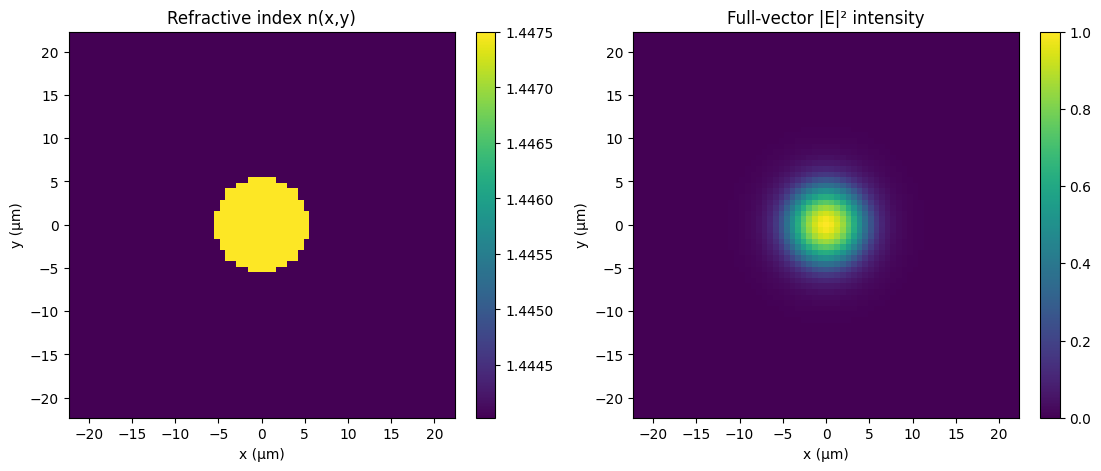

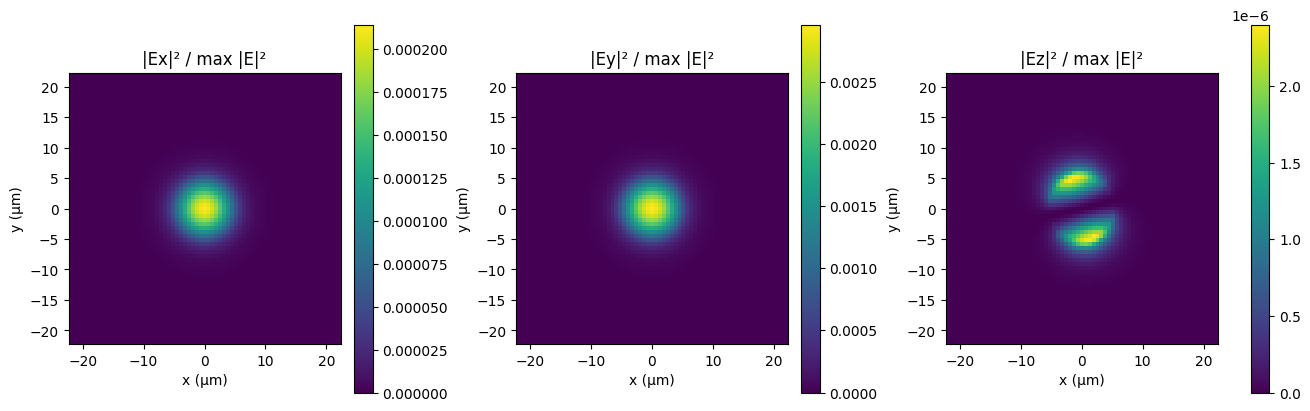

In [4]:
out=Path('full_vector_results');out.mkdir(exist_ok=True)
xy=solution['xy_um']; X,Y=np.meshgrid(xy,xy)
I=mode['field_intensity']
fig,axs=plt.subplots(1,2,figsize=(11,4.6),constrained_layout=True)
im=axs[0].pcolormesh(X,Y,solution['index_map'],shading='auto');axs[0].set(title='Refractive index n(x,y)',xlabel='x (µm)',ylabel='y (µm)',aspect='equal');fig.colorbar(im,ax=axs[0]);
im=axs[1].pcolormesh(X,Y,I,shading='auto');axs[1].set(title='Full-vector |E|² intensity',xlabel='x (µm)',ylabel='y (µm)',aspect='equal');fig.colorbar(im,ax=axs[1]);fig.savefig(out/'vector_index_and_total.png',dpi=150);plt.show()
fig,axs=plt.subplots(1,3,figsize=(13,4),constrained_layout=True)
for ax,name in zip(axs,('Ex','Ey','Ez')):
    img=(abs(mode[name])**2)/max(I.max(),1e-30)
    im=ax.pcolormesh(X,Y,img,shading='auto',vmin=0);ax.set(title='|'+name+'|² / max |E|²',xlabel='x (µm)',ylabel='y (µm)',aspect='equal');fig.colorbar(im,ax=ax)
fig.savefig(out/'vector_Ex_Ey_Ez.png',dpi=150);plt.show()

## 5. MFD and Aeff from field integrations
Unlike the usual Gaussian-fit MFD, these quantities are calculated from the actual vector electric-field distribution. Both MFD definitions are provided and must **not be conflated**.

In [5]:
from pandas import DataFrame
fields=[('Effective index neff',mode['neff'],'1'),('MFD second moment',mode['MFD_2nd_um'],'µm'),('MFD near-field PII-like',mode['MFD_PII_um'],'µm'),('Aeff',mode['Aeff_um2'],'µm²'),('Longitudinal |Ez|² fraction',float(np.sum(abs(mode['Ez'])**2)/np.sum(abs(mode['Ex'])**2+abs(mode['Ey'])**2+abs(mode['Ez'])**2)),'1'),('Core intensity fraction',mode['core_power_fraction'],'1'),('Boundary tail fraction',mode['edge_power_fraction'],'1')]
df=DataFrame(fields,columns=['quantity','value','unit'])
display(df)
df.to_csv(out/'vector_metrics.csv',index=False)
print('Aeff uses full |E|², not |H|² or transverse scalar intensity.')

,quantity,value,unit
0,Effective index neff,1.445712,1
1,MFD second moment,12.791201,µm
2,MFD near-field PII-like,12.558175,µm
3,Aeff,121.355050,µm²
4,Longitudinal |Ez|² fraction,0.000742,1
5,Core intensity fraction,0.795712,1
6,Boundary tail fraction,0.000002,1


Aeff uses full |E|², not |H|² or transverse scalar intensity.


## 6. Mesh-convergence diagnostics
**Do not assume monotonic convergence:** a Cartesian grid approximates a curved core boundary with stair steps. Increase mesh and external domain separately. A small algebraic eigenresidual does not prove physical accuracy.

,grid_n,neff,HE11_exact,abs_neff_error,MFD_2nd_um,MFD_PII_um,Aeff_um2,boundary_power
0,45,1.445753,1.445717,0.000036,12.794117,12.682200,122.196741,0.000009
1,57,1.445661,1.445717,0.000056,12.727075,12.502098,119.021586,0.000005
2,69,1.445712,1.445717,0.000005,12.791201,12.558170,121.355050,0.000002
3,81,1.445702,1.445717,0.000015,12.790387,12.529672,121.136446,0.000001


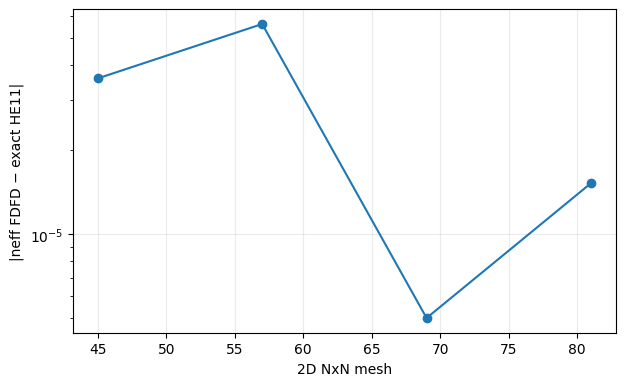

In [6]:
import pandas as pd
MESH_GRID_N = [45,57,69,81]
rows=[]
for n in MESH_GRID_N:
    c=Configuration(**{**config.__dict__,'grid_n':n})
    s=solve(c,modes=3);v=s['modes'][0]
    rows.append({'grid_n':n,'neff':v['neff'],'HE11_exact':he11_exact_step(c) if c.profile=='step' else np.nan,
                 'abs_neff_error':abs(v['neff']-he11_exact_step(c)) if c.profile=='step' else np.nan,
                 'MFD_2nd_um':v['MFD_2nd_um'],'MFD_PII_um':v['MFD_PII_um'],'Aeff_um2':v['Aeff_um2'],
                 'boundary_power':v['edge_power_fraction']})
mesh=pd.DataFrame(rows);display(mesh)
mesh.to_csv(out/'vector_mesh_convergence.csv',index=False)
fig,ax=plt.subplots(figsize=(7,4.2))
if config.profile=='step': ax.semilogy(mesh.grid_n,mesh.abs_neff_error,'o-');ax.set_ylabel('|neff FDFD − exact HE11|')
else: ax.plot(mesh.grid_n,mesh.neff,'o-');ax.set_ylabel('Vector neff')
ax.set_xlabel('2D NxN mesh');ax.grid(alpha=.25);fig.savefig(out/'vector_mesh_convergence.png',dpi=150);plt.show()

## 7. Synthetic Gaussian unit check for field integrals

In [7]:
xx=np.linspace(-20,20,201);X,Y=np.meshgrid(xx,xx);w=5.
Igauss=np.exp(-2*(X**2+Y**2)/w**2)
check=integrate_intensity(Igauss,xx)
assert abs(check['MFD_2nd_um']-2*w)<.01
assert abs(check['MFD_PII_um']-2*w)<.02
assert abs(check['Aeff_um2']-np.pi*w*w)<.01
print('Gaussian integral test: PASS',check)

Gaussian integral test: PASS {'Aeff_um2': np.float64(78.53981633974396), 'MFD_2nd_um': np.float64(9.99999999999971), 'MFD_PII_um': np.float64(10.008001065813522), 'centroid_x_um': 1.2303799087759338e-16, 'centroid_y_um': 1.1580046200244082e-16, 'power_integral': 39.26990816987205}


## 8. Export to Universal Silica Fiber Lab (GitHub Pages)
The JSON contains **calculated** vector modal metrics and downsampled intensity maps for browser visualization. A separate NPZ contains all complex Ex/Ey/Ez and Hx/Hy/Hz arrays. Imported results are snapshots; modifying the browser scalar inputs does not recompute them.

In [8]:
import zipfile
json_path=out/'vector_mode_result.json'
portable=export_result(solution,json_path,field_stride=2)
save_full_fields(solution,out/'vector_fields_complex.npz')
portable['validation']['exact_HE11_neff']=exact
portable['validation']['abs_neff_error_vs_exact']=abs(mode['neff']-exact) if exact is not None else None
json_path.write_text(json.dumps(portable,ensure_ascii=False,indent=2))
archive=Path('LSCNS_Full_Vector_Results.zip')
with zipfile.ZipFile(archive,'w',compression=zipfile.ZIP_DEFLATED) as z:
    for p in out.glob('*'):z.write(p,arcname=p.name)
print('Web import file:',json_path.resolve())
print('Full complex fields:',(out/'vector_fields_complex.npz').resolve())
print('Downloadable report ZIP:',archive.resolve())
try:
    from google.colab import files
    files.download(str(json_path))
except ImportError:
    print('Outside Colab: file saved locally, no automatic download')

Web import file: /mnt/data/full_vector_upgrade/full_vector_results/vector_mode_result.json
Full complex fields: /mnt/data/full_vector_upgrade/full_vector_results/vector_fields_complex.npz
Downloadable report ZIP: /mnt/data/full_vector_upgrade/LSCNS_Full_Vector_Results.zip
Outside Colab: file saved locally, no automatic download
